# 🛰️ Solución Maestra: Logística Geoespacial en Baja California

Este notebook resuelve el caso práctico de clusterización geoespacial. Compararemos cómo dos algoritmos distintos (K-Means y DBSCAN) resuelven dos problemas de negocio completamente diferentes usando los mismos datos de GPS.

**Misión 1 (Estratégica):** Ubicar 3 Centros de Distribución (K-Means).
**Misión 2 (Operativa):** Detectar zonas de alta demanda y aislar entregas rurales (DBSCAN).

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler

# 1. Cargar Datos
df = pd.read_csv('datasets/logistica_baja_california.csv')

# Aislar coordenadas (La matriz X)
X = df[['Longitud', 'Latitud']].values # Longitud en X, Latitud en Y para el mapa

# 2. Escalamiento (Vital para DBSCAN)
X_scaled = StandardScaler().fit_transform(X)

## 🏭 Misión 1: K-Means (Los 3 Centros de Distribución)
Buscamos los 3 "centros de gravedad" de la demanda total. K-Means intentará minimizar la distancia de todos los pedidos hacia su centroide más cercano.

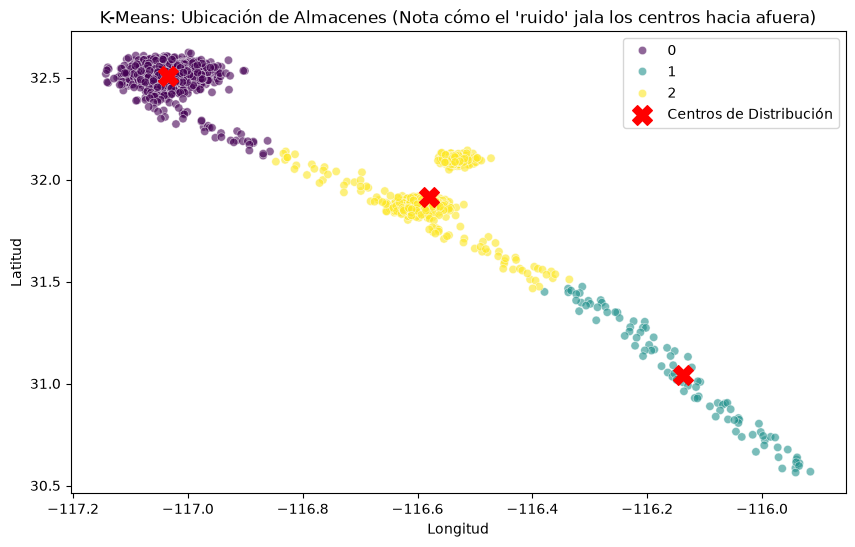

In [22]:
# Entrenar K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

# Extraer centroides (desescalarlos para graficarlos en coordenadas reales)
scaler = StandardScaler().fit(X)
centroides_reales = scaler.inverse_transform(kmeans.cluster_centers_)

# Graficar
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['Longitud'], y=df['Latitud'], hue=labels_kmeans, palette='viridis', alpha=0.6)
plt.scatter(centroides_reales[:, 0], centroides_reales[:, 1], c='red', s=200, marker='X', label='Centros de Distribución')
plt.title("K-Means: Ubicación de Almacenes (Nota cómo el 'ruido' jala los centros hacia afuera)")
plt.legend()
plt.show()

## 🚨 Misión 2: DBSCAN (Zonas de Alta Demanda vs Ruido Rural)
Buscamos densidad urbana pura. DBSCAN agrupará las zonas donde hay muchos pedidos juntos y catalogará las entregas rurales aisladas como ruido (-1), ignorándolas.

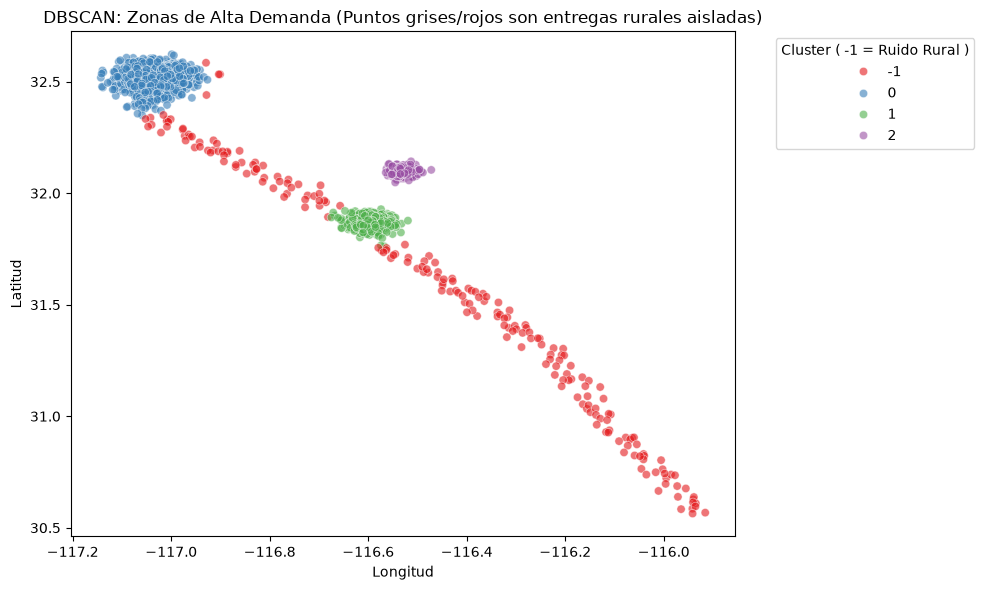

In [21]:
# Entrenar DBSCAN (Parámetros ajustados empíricamente para coordenadas escaladas)
dbscan = DBSCAN(eps=0.1, min_samples=15)
labels_dbscan = dbscan.fit_predict(X_scaled)

# Graficar
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['Longitud'], y=df['Latitud'], hue=labels_dbscan, palette='Set1', alpha=0.6)
plt.title("DBSCAN: Zonas de Alta Demanda (Puntos grises/rojos son entregas rurales aisladas)")
plt.legend(title="Cluster ( -1 = Ruido Rural )", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()